In [ ]:
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet

from sklearn.metrics import mean_squared_error, r2_score


In [ ]:
# ------------------------------------------------------------
# 2. CREATE A SAMPLE DATASET
# ------------------------------------------------------------

# We create 200 observations and 10 features.
# Only 5 features are actually useful.
# This helps us demonstrate feature selection.

X, y = make_regression(
    n_samples=200,
    n_features=10,
    n_informative=5,
    noise=20,
    random_state=42
)


In [ ]:
# Give meaningful names to the features
feature_names = [
    "Area", "Bedrooms", "Age", "Location", "Parking",
    "Garden", "Floor", "Distance", "School", "Transport"
]


In [ ]:
# Create DataFrame
df = pd.DataFrame(X, columns=feature_names)

print("Dataset:")
print(df.head())



Dataset:
       Area  Bedrooms       Age  Location   Parking    Garden     Floor  \
0  1.262584  0.932591 -0.399636  0.224685 -1.760809  1.726964 -0.372833   
1 -0.295480 -0.370011 -0.109610 -0.088363  1.598647 -0.436386  0.006422   
2 -0.692421 -1.320023  0.194607 -0.742471 -0.037037 -0.622649  1.695051   
3 -1.406661 -0.725744  0.026091  0.517659 -0.755383 -0.624819 -1.279577   
4 -2.872262 -1.594703 -0.147603 -0.466037 -0.532701  0.323168 -1.768439   

   Distance    School  Transport  
0  0.722381 -1.525656  -1.418366  
1  0.546284  0.560919  -0.258796  
2  0.043602 -0.429302  -0.611769  
3 -1.840874 -0.611518   0.186767  
4  0.140886 -1.169917   0.513600  


In [ ]:
# ------------------------------------------------------------
# 3. SPLIT DATA INTO TRAINING AND TESTING
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))



Training samples: 160
Testing samples: 40


In [ ]:
# 4. LINEAR REGRESSION
# ============================================================

# Create model
linear_model = LinearRegression()

# Train model
linear_model.fit(X_train, y_train)

# Make predictions
linear_pred = linear_model.predict(X_test)
linear_pred

array([ -29.75772096,    2.73184135,  137.18042866,  -92.52715947,
         33.8921631 ,  169.35756703,  -53.19577657,  -29.82698156,
         43.25178628,    0.45180013,  -16.55163869,   47.12906435,
        -24.76298915, -127.82752246,   85.45131742, -146.2615723 ,
         27.77042267,  164.78929532, -103.69949718,  -17.22086351,
        -47.76961031,   70.3441662 ,  -20.19782856,   85.30150992,
         -9.19886914,    4.29946091,   37.94407241,   -0.21093156,
         71.42461919,   14.24390083,   -1.93147209,  126.45151801,
         46.64940674,   99.63191344,  192.14611572,   65.1273779 ,
         60.14742682,   17.18171662,   65.57096746,    9.35619052])

In [ ]:
# Calculate performance
linear_mse = mean_squared_error(y_test, linear_pred)
linear_r2 = r2_score(y_test, linear_pred)

print("\n==============================")
print("LINEAR REGRESSION")
print("==============================")
print("MSE:", round(linear_mse, 2))
print("R2:", round(linear_r2, 3))



LINEAR REGRESSION
MSE: 325.12
R2: 0.949


In [ ]:
# ------------------------------------------------------------
# Display Linear Regression coefficients
# ------------------------------------------------------------

linear_coef = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": linear_model.coef_
})

print("\nLinear Regression Coefficients:")
print(linear_coef)



Linear Regression Coefficients:
     Feature  Coefficient
0       Area     1.517580
1   Bedrooms    -1.805324
2        Age     7.122031
3   Location    79.956193
4    Parking     1.092844
5     Garden    36.273153
6      Floor     8.599333
7   Distance    40.753260
8     School     1.208466
9  Transport    -1.103896


**Regularization Approach**

In [ ]:
# 5. RIDGE REGRESSION - L2 REGULARIZATION
# ============================================================
# Ridge uses L2 penalty.
# Larger alpha = stronger regularization.

ridge_model = Ridge(alpha=50)


In [ ]:
# Train
ridge_model.fit(X_train, y_train)

# Predict
ridge_pred = ridge_model.predict(X_test)
ridge_pred

array([ -25.2136272 ,   -1.85081539,  105.15927815,  -68.56227954,
         30.09862262,  128.7408049 ,  -37.59041036,  -16.69941632,
         35.53536169,   -0.96531079,  -14.0645026 ,   39.68198292,
        -16.50835671,  -93.89596861,   68.57736872, -111.3265558 ,
         25.66540488,  117.66943549,  -72.8511683 ,  -16.18687665,
        -35.77938016,   51.89827628,  -14.69835947,   65.18672225,
         -9.97394661,    7.09950966,   24.61623183,    0.90725472,
         57.96956454,   16.16153068,   -7.64730091,  103.24770298,
         37.35334577,   71.25856879,  144.20855354,   51.49831335,
         42.74530931,   15.46486595,   51.70172231,   13.4666693 ])

In [ ]:
# Evaluate
ridge_mse = mean_squared_error(y_test, ridge_pred)
ridge_r2 = r2_score(y_test, ridge_pred)
print("\n==============================")
print("RIDGE REGRESSION - L2")
print("==============================")
print("MSE:", round(ridge_mse, 2))
print("R2:", round(ridge_r2, 3))


RIDGE REGRESSION - L2
MSE: 866.39
R2: 0.863


In [ ]:
# Display coefficients
ridge_coef = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": ridge_model.coef_
})

print("\nRidge Coefficients:")
print(ridge_coef)



Ridge Coefficients:
     Feature  Coefficient
0       Area     2.567518
1   Bedrooms    -3.002563
2        Age     3.333069
3   Location    59.981645
4    Parking    -0.189533
5     Garden    29.523967
6      Floor     7.579014
7   Distance    30.494511
8     School     1.263240
9  Transport    -1.867823


# LI Regularization- LASSO

In [ ]:
# 6. LASSO REGRESSION - L1 REGULARIZATION
# ============================================================

# Lasso uses L1 penalty.
# Lasso can make some coefficients exactly ZERO.

lasso_model = Lasso(alpha=10)


In [ ]:

# Train
lasso_model.fit(X_train, y_train)

# Predict
lasso_pred = lasso_model.predict(X_test)
lasso_pred

array([ -28.71906922,    2.15076343,  108.75250806,  -68.66821549,
         21.26299578,  161.14986669,  -29.94318716,  -58.75045002,
         21.20344462,    1.39381158,    3.48319008,   50.42022803,
        -30.40903745, -104.06992112,   89.3201451 , -135.32629418,
         19.01139661,  135.63920167,  -92.77117829,  -12.91641752,
        -59.85965859,   61.92462184,   -9.39774253,   59.96312384,
         10.70196115,    5.62315094,   17.37511071,   -9.98695779,
         59.2583434 ,    3.4471875 ,   -0.72443806,  110.84201699,
         16.21572787,   85.18841877,  151.41293172,   59.8496027 ,
         40.21517185,    6.58777156,   69.8571661 ,   29.35086354])

In [ ]:
# Evaluate
lasso_mse = mean_squared_error(y_test, lasso_pred)
lasso_r2 = r2_score(y_test, lasso_pred)

print("\n==============================")
print("LASSO REGRESSION - L1")
print("==============================")
print("MSE:", round(lasso_mse, 2))
print("R2:", round(lasso_r2, 3))


LASSO REGRESSION - L1
MSE: 761.83
R2: 0.88


In [ ]:
# Display coefficients
lasso_coef = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": lasso_model.coef_
})

print("\nLasso Coefficients:")
print(lasso_coef)



Lasso Coefficients:
     Feature  Coefficient
0       Area     0.000000
1   Bedrooms    -0.000000
2        Age     0.000000
3   Location    70.505308
4    Parking    -0.000000
5     Garden    28.814358
6      Floor     0.000000
7   Distance    29.188430
8     School     0.000000
9  Transport    -0.000000


In [ ]:
# Count zero coefficients
zero_features = np.sum(lasso_model.coef_ == 0)
zero_features

np.int64(7)

In [ ]:
print("\nNumber of coefficients equal to ZERO:", zero_features)


Number of coefficients equal to ZERO: 7


# ElasticNet Regularization

In [ ]:
# 7. ELASTIC NET
# ============================================================

# Elastic Net combines L1 + L2.
#
# l1_ratio = 0.5 means a combination of L1 and L2.
#
# l1_ratio closer to 1 → more Lasso-like
# l1_ratio closer to 0 → more Ridge-like

elastic_model = ElasticNet(
    alpha=10,
    l1_ratio=0.5
)


In [ ]:
# Train
elastic_model.fit(X_train, y_train)


ElasticNet(alpha=10)

In [ ]:
# Predict
elastic_pred = elastic_model.predict(X_test)
elastic_pred

array([ -2.03188553,   4.50910684,  26.61408746,  -7.84263259,
        11.88032817,  31.89417473,  -2.63991692,   1.20614337,
        12.33752142,   3.5287273 ,   2.23886794,  13.8182441 ,
         0.96385046, -16.02115337,  19.55050106, -18.76578198,
        12.58290634,  27.00021234,  -9.98796512,   0.72558603,
        -4.00699398,  13.95458162,   1.64736511,  17.87321559,
         2.89189324,   6.80582324,   9.51220647,   4.27522323,
        17.50011531,   8.44003038,   0.47955848,  27.56317456,
        11.87390975,  18.11150447,  33.7037885 ,  15.42684151,
        12.25307027,   7.45839103,  15.92533984,   9.41450478])

In [ ]:
# Evaluate
elastic_mse = mean_squared_error(y_test, elastic_pred)
elastic_r2 = r2_score(y_test, elastic_pred)

print("\n==============================")
print("ELASTIC NET - L1 + L2")
print("==============================")
print("MSE:", round(elastic_mse, 2))
print("R2:", round(elastic_r2, 3))


ELASTIC NET - L1 + L2
MSE: 4973.97
R2: 0.215


In [ ]:
# Display coefficients
elastic_coef = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": elastic_model.coef_
})

print("\nElastic Net Coefficients:")
print(elastic_coef)


Elastic Net Coefficients:
     Feature  Coefficient
0       Area     0.371588
1   Bedrooms    -0.770968
2        Age    -0.000000
3   Location    12.212023
4    Parking    -0.000000
5     Garden     6.834328
6      Floor     1.651275
7   Distance     5.646459
8     School     0.000000
9  Transport    -0.422078


In [ ]:
# ============================================================
# 8. COMPARE ALL MODELS
# ============================================================

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge",
        "Lasso",
        "Elastic Net"
    ],

    "MSE": [
        linear_mse,
        ridge_mse,
        lasso_mse,
        elastic_mse
    ],

    "R2": [
        linear_r2,
        ridge_r2,
        lasso_r2,
        elastic_r2
    ]
})

results

,Model,MSE,R2
0,Linear Regression,325.115809,0.948693
1,Ridge,866.391956,0.863273
2,Lasso,761.828647,0.879774
3,Elastic Net,4973.970562,0.215049


In [ ]:
print("\n==============================")
print("MODEL COMPARISON")
print("==============================")

print(results.round(3))



MODEL COMPARISON
               Model       MSE     R2
0  Linear Regression   325.116  0.949
1              Ridge   866.392  0.863
2              Lasso   761.829  0.880
3        Elastic Net  4973.971  0.215


In [ ]:
# ============================================================
# 9. COMPARE COEFFICIENTS
# ============================================================

coefficient_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Linear": linear_model.coef_,
    "Ridge": ridge_model.coef_,
    "Lasso": lasso_model.coef_,
    "Elastic Net": elastic_model.coef_
})


In [ ]:
print("\n==============================")
print("COEFFICIENT COMPARISON")
print("==============================")

print(coefficient_comparison.round(3))


COEFFICIENT COMPARISON
     Feature  Linear   Ridge   Lasso  Elastic Net
0       Area   1.518   2.568   0.000        0.372
1   Bedrooms  -1.805  -3.003  -0.000       -0.771
2        Age   7.122   3.333   0.000       -0.000
3   Location  79.956  59.982  70.505       12.212
4    Parking   1.093  -0.190  -0.000       -0.000
5     Garden  36.273  29.524  28.814        6.834
6      Floor   8.599   7.579   0.000        1.651
7   Distance  40.753  30.495  29.188        5.646
8     School   1.208   1.263   0.000        0.000
9  Transport  -1.104  -1.868  -0.000       -0.422


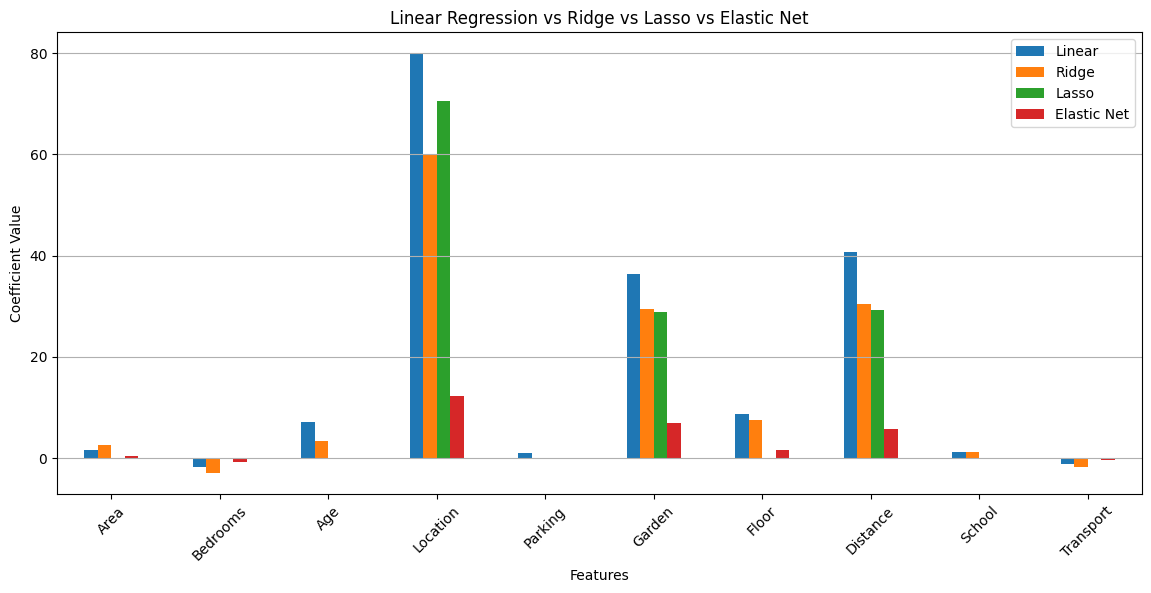

In [ ]:
# ============================================================
# 10. VISUALIZE COEFFICIENTS
# ============================================================

coefficient_comparison.set_index("Feature").plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Linear Regression vs Ridge vs Lasso vs Elastic Net")
plt.ylabel("Coefficient Value")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.show()


In [ ]:
# ============================================================
# 11. EFFECT OF ALPHA ON LASSO
# ============================================================

# Let's see what happens when we increase alpha.

alphas = [0.01, 0.1, 1, 10, 100]

print("\n==============================")
print("EFFECT OF ALPHA ON LASSO")
print("==============================")



EFFECT OF ALPHA ON LASSO


In [ ]:
# 11. EFFECT OF ALPHA ON LASSO
# ============================================================

# Let's see what happens when we increase alpha.

alphas = [0.01, 0.1, 1, 10, 100]

print("\n==============================")
print("EFFECT OF ALPHA ON LASSO")
print("==============================")

for alpha in alphas:

    # Create Lasso model
    model = Lasso(alpha=alpha)

    # Train
    model.fit(X_train, y_train)

    # Count coefficients that became zero
    zero_count = np.sum(model.coef_ == 0)

    print(
        "Alpha =", alpha,
        "| Zero coefficients =", zero_count
    )




EFFECT OF ALPHA ON LASSO
Alpha = 0.01 | Zero coefficients = 0
Alpha = 0.1 | Zero coefficients = 0
Alpha = 1 | Zero coefficients = 1
Alpha = 10 | Zero coefficients = 7
Alpha = 100 | Zero coefficients = 10


In [ ]:
# ============================================================
# 12. EFFECT OF L1_RATIO ON ELASTIC NET
# ============================================================

print("\n==============================")
print("EFFECT OF L1_RATIO")
print("==============================")

ratios = [0.1, 0.3, 0.5, 0.7, 0.9]

for ratio in ratios:

    model = ElasticNet(
        alpha=10,
        l1_ratio=ratio
    )

    model.fit(X_train, y_train)

    zero_count = np.sum(model.coef_ == 0)

    print(
        "L1 Ratio =", ratio,
        "| Zero coefficients =", zero_count
    )



EFFECT OF L1_RATIO
L1 Ratio = 0.1 | Zero coefficients = 0
L1 Ratio = 0.3 | Zero coefficients = 2
L1 Ratio = 0.5 | Zero coefficients = 3
L1 Ratio = 0.7 | Zero coefficients = 5
L1 Ratio = 0.9 | Zero coefficients = 6


In [ ]:
# ============================================================
# 13. SIMPLE FINAL SUMMARY
# ============================================================

print("\n======================================")
print("REGULARIZATION SUMMARY")
print("======================================")

print("""
Linear Regression
→ No regularization

Ridge
→ L2 regularization
→ Shrinks coefficients

Lasso
→ L1 regularization
→ Can make coefficients ZERO
→ Useful for feature selection

Elastic Net
→ Combination of L1 + L2
→ Shrinks coefficients
→ Can also remove some features
""")


REGULARIZATION SUMMARY

Linear Regression
→ No regularization

Ridge
→ L2 regularization
→ Shrinks coefficients

Lasso
→ L1 regularization
→ Can make coefficients ZERO
→ Useful for feature selection

Elastic Net
→ Combination of L1 + L2
→ Shrinks coefficients
→ Can also remove some features

